# Verifying the Preliminary Visualization: Telco Customer Churn

**CISC7204 Assignment 1 — optional Jupyter Notebook deliverable**

| | |
|---|---|
| Course | CISC7204 Data Science and Data Visualization |
| Student | MC652723 XIE AN |
| Team project | *Who Will Churn Next? Customer Churn Prediction and User-Behavior Visualization for a California Telecom Operator* |
| My responsibility | EDA visualization design, model construction and evaluation |
| Data | Kaggle **Telco Customer Churn** — 7,043 customers x 21 attributes (California, USA) |

This notebook is the Python 3 verification of **Figure 1** in the proposal. It loads the raw CSV,
repeats the data-preparation steps described in Section 3, rebuilds the four exploratory panels of
Figure 1 (churn rate by contract with a chi-square test, monthly-charge densities, tenure densities,
and the correlation heatmap), regenerates the figure file embedded in the proposal, and finally
**asserts that every number quoted in the proposal is reproducible from the raw data**.

Run it from the folder that contains `telco_churn.csv` (the notebook locates the file automatically).


## 0. Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from pathlib import Path

%matplotlib inline
sns.set_theme(style="whitegrid", context="talk")

pd.set_option("display.width", 120)
print("pandas", pd.__version__, "| seaborn", sns.__version__)


pandas 3.0.3 | seaborn 0.13.2


## 1. Load the data set

The Kaggle *Telco Customer Churn* table ships as a single CSV: one row per customer, 21 columns
covering demographics, subscribed services, contract and billing terms, tenure, charges, and the
churn label that we are trying to explain.


In [2]:
# The CSV sits next to this notebook; fall back to the parent folder if run elsewhere
DATA_DIR = next(
    (p for p in [Path.cwd(), Path.cwd() / "output", Path.cwd().parent]
     if (p / "telco_churn.csv").exists()),
    Path.cwd(),
)
CSV = DATA_DIR / "telco_churn.csv"

df = pd.read_csv(CSV)
print("loaded:", CSV)
print("shape :", df.shape)
df.head()


loaded: D:\研究生\CISC7204\assignment1\proposal_build\output\telco_churn.csv
shape : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Structure of the table: which fields are numeric and which are categorical
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
other_cols = [c for c in df.columns if c not in numeric_cols]

print(f"numeric fields ({len(numeric_cols)}):\n  {numeric_cols}\n")
print(f"categorical / text fields ({len(other_cols)}):\n  {other_cols}")


numeric fields (3):
  ['SeniorCitizen', 'tenure', 'MonthlyCharges']

categorical / text fields (18):
  ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


## 2. Data preparation

Section 3 of the proposal specifies how the raw table is made analysis-ready. The only real
data-quality problem is in `TotalCharges`: it is stored as text, and 11 customers have a blank
string instead of a number.


In [4]:
# Coerce TotalCharges from text to numeric: blank strings become NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

n_blank = int(df["TotalCharges"].isna().sum())
print("blank / non-numeric TotalCharges entries:", n_blank)

# Inspect WHO is missing: these are the customers who have not been billed yet
blank_rows = df[df["TotalCharges"].isna()]
print("their tenure values:", blank_rows["tenure"].tolist())


blank / non-numeric TotalCharges entries: 11
their tenure values: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [5]:
# Every one of the 11 is a brand-new customer (tenure = 0 months) with no billing history yet,
# so there is no information to recover and the column median is a safe, documented fill.
median_total_charges = df["TotalCharges"].median()
df["TotalCharges"] = df["TotalCharges"].fillna(median_total_charges)

print(f"imputation value (median TotalCharges): {median_total_charges:,.2f}")
print("remaining missing values in the whole table:", int(df.isna().sum().sum()))


imputation value (median TotalCharges): 1,397.47
remaining missing values in the whole table: 0


In [6]:
# Encode the target: churn is a binary outcome for the (future) classification models
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
print(df["Churn"].value_counts().to_string())


Churn
No     5174
Yes    1869


## 3. Churn overview

Before any chart, establish the base rate. This number drives the whole modelling plan: with a
minority positive class, **accuracy is a misleading metric** and Precision / Recall / ROC-AUC are
required.


In [7]:
churn_rate = df["ChurnFlag"].mean()
print(f"customers : {len(df):,}")
print(f"churned   : {df['ChurnFlag'].sum():,}")
print(f"retained  : {int((1 - df['ChurnFlag']).sum()):,}")
print(f"churn rate: {churn_rate:.1%}")


customers : 7,043
churned   : 1,869
retained  : 5,174
churn rate: 26.5%


## 4. Exploratory analysis — who churns?

This section follows the EDA plan set out in Section 3 of the proposal: boxplots / KDE density plots
for the spending differences of churned customers, a heatmap for feature collinearity, and a
chi-square test for the effect of contract type.


### 4.1 Contract type and churn — chi-square test of independence

Contract type is a categorical driver, so the right test is a chi-square test of independence on the
contingency table rather than a correlation.


In [8]:
contract_table = pd.crosstab(df["Contract"], df["Churn"])

chi2, p_value, dof, expected = chi2_contingency(contract_table)
contract_rate = (contract_table["Yes"] / contract_table.sum(axis=1) * 100).round(1)

print(contract_table.to_string(), "\n")
print("churn rate by contract (%):")
print(contract_rate.to_string(), "\n")
print(f"chi-square({dof}) = {chi2:.0f},  p = {p_value:.2e}")


Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48 

churn rate by contract (%):
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8 

chi-square(2) = 1185,  p = 5.86e-258


**Reading.** Month-to-month customers churn at **42.7%**, against **11.3%** on one-year and
**2.8%** on two-year contracts. With chi-square(2) = 1,185 and p < 0.001 the association is
overwhelming: contract lock-in, not price alone, is the dominant churn marker. This is the single
strongest categorical driver surfaced by the EDA, and it is why contract type must be one-hot encoded
in the model.


### 4.2 Spending and tenure differences between churned and retained customers


In [9]:
summary = df.groupby("Churn").agg(
    customers=("Churn", "size"),
    monthly_mean=("MonthlyCharges", "mean"),
    monthly_median=("MonthlyCharges", "median"),
    tenure_median=("tenure", "median"),
    total_median=("TotalCharges", "median"),
).round(1)
summary


,customers,monthly_mean,monthly_median,tenure_median,total_median
Churn,,,,,
No,5174,61.3,64.4,38.0,1679.5
Yes,1869,74.4,79.6,10.0,703.6


**Reading.** Churned customers pay **more** per month on average (US$74.4 vs US$61.3) yet their
median tenure is only **10 months** against **38 months** for retained customers. The risk segment is
therefore *new, high-charge* subscribers — a pattern the KDE panels in Figure 1 make visible, and the
target group for retention offers.


### 4.3 Other categorical drivers (payment method, internet service)

The same chi-square test is applied to the remaining categorical candidates so the modelling choice is
evidence-based rather than assumed.


In [10]:
for col in ["PaymentMethod", "InternetService"]:
    table = pd.crosstab(df[col], df["Churn"])
    rate = (table["Yes"] / table.sum(axis=1) * 100).round(1)
    c2, pv, d, _ = chi2_contingency(table)
    print(f"{col}: chi-square({d}) = {c2:.0f}, p = {pv:.1e}")
    print(rate.to_string(), "\n")


PaymentMethod: chi-square(3) = 648, p = 3.7e-140
PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1 

InternetService: chi-square(2) = 732, p = 9.6e-160
InternetService
DSL            19.0
Fiber optic    41.9
No              7.4 



### 4.4 Collinearity check — correlation heatmap

Before fitting a logistic regression we need to know which numeric features carry overlapping
information. `TotalCharges` is essentially `tenure` x `MonthlyCharges`, so a strong correlation is
expected.


In [11]:
# The encoded outcome is labelled "Churn" here so the heatmap reads exactly as in the proposal
numeric_block = df[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]].copy()
numeric_block["Churn"] = df["ChurnFlag"]

corr = numeric_block.corr().round(2)
corr


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
SeniorCitizen,1.00,0.02,0.22,0.10,0.15
tenure,0.02,1.00,0.25,0.83,-0.35
MonthlyCharges,0.22,0.25,1.00,0.65,0.19
TotalCharges,0.10,0.83,0.65,1.00,-0.20
Churn,0.15,-0.35,0.19,-0.20,1.00


**Reading.** `tenure` has the strongest linear association with churn (**r = -0.35**: the longer a
customer stays, the less likely they are to leave), while `MonthlyCharges` pushes the other way
(r = +0.19). Its correlation with `TotalCharges` is **r = 0.83**, which is the collinearity flagged in
panel (d) of Figure 1 — the modelling step must address it (drop one of the pair, or rely on
regularisation) before interpreting logistic-regression coefficients.


## 5. Figure 1 — the four exploratory panels

The chart below is the visual embedded in Section 4 of the proposal. Panels (a)-(d) correspond to the
four analyses above, and the file is rewritten to `telco_churn_figure.png` so the proposal asset is
fully reproducible from this notebook.


figure written to: D:\研究生\CISC7204\assignment1\proposal_build\output\telco_churn_figure.png


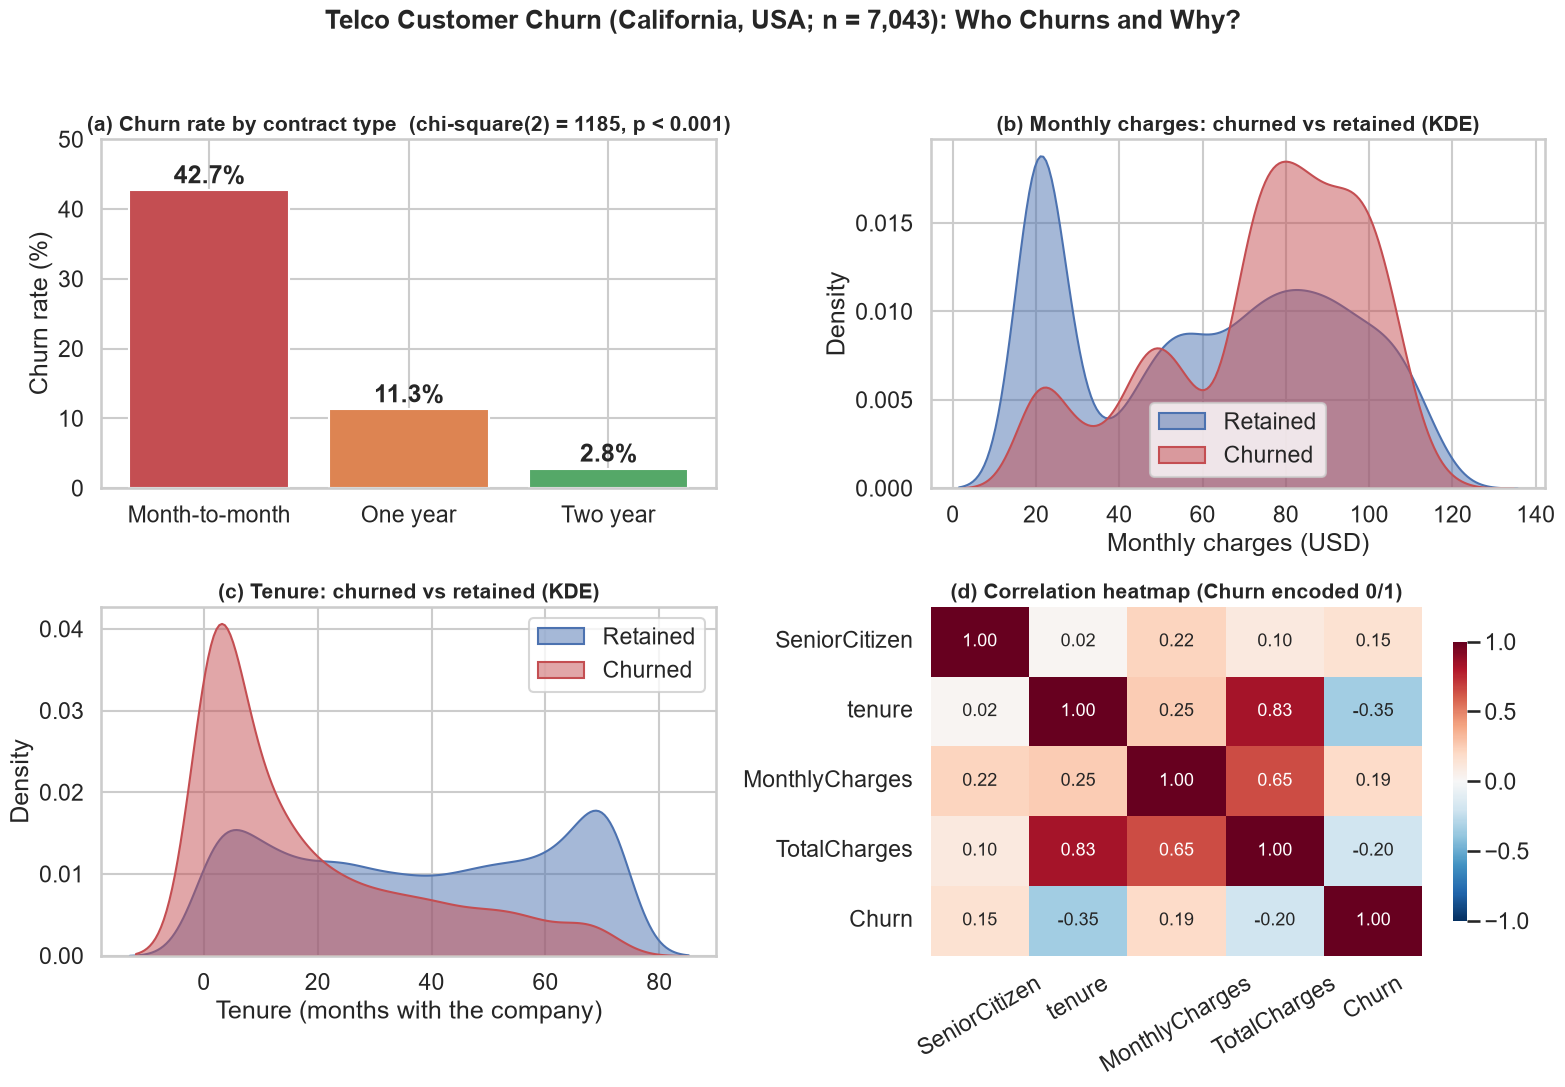

In [12]:
# Figure 1 of the proposal: four exploratory panels
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Telco Customer Churn (California, USA; n = 7,043): Who Churns and Why?",
             fontsize=19, fontweight="bold", y=0.995)

# (a) churn rate by contract type + chi-square test
ax = axes[0, 0]
order = ["Month-to-month", "One year", "Two year"]
values = [contract_rate[c] for c in order]
ax.bar(range(3), values, color=["#C44E52", "#DD8452", "#55A868"])
ax.set_xticks(range(3))
ax.set_xticklabels(["Month-to-month", "One year", "Two year"])
for i, v in enumerate(values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")
ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, 50)
ax.set_title(f"(a) Churn rate by contract type  (chi-square({dof}) = {chi2:.0f}, p < 0.001)",
             fontsize=15, fontweight="bold")

# (b) monthly charges, churned vs retained
ax = axes[0, 1]
sns.kdeplot(x=df.loc[df["Churn"] == "No", "MonthlyCharges"], ax=ax, fill=True,
            label="Retained", color="#4C72B0", alpha=0.5)
sns.kdeplot(x=df.loc[df["Churn"] == "Yes", "MonthlyCharges"], ax=ax, fill=True,
            label="Churned", color="#C44E52", alpha=0.5)
ax.legend()
ax.set_xlabel("Monthly charges (USD)")
ax.set_ylabel("Density")
ax.set_title("(b) Monthly charges: churned vs retained (KDE)", fontsize=15, fontweight="bold")

# (c) tenure, churned vs retained
ax = axes[1, 0]
sns.kdeplot(x=df.loc[df["Churn"] == "No", "tenure"], ax=ax, fill=True,
            label="Retained", color="#4C72B0", alpha=0.5)
sns.kdeplot(x=df.loc[df["Churn"] == "Yes", "tenure"], ax=ax, fill=True,
            label="Churned", color="#C44E52", alpha=0.5)
ax.legend()
ax.set_xlabel("Tenure (months with the company)")
ax.set_ylabel("Density")
ax.set_title("(c) Tenure: churned vs retained (KDE)", fontsize=15, fontweight="bold")

# (d) correlation heatmap
ax = axes[1, 1]
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            ax=ax, annot_kws={"size": 13}, cbar_kws={"shrink": 0.8})
ax.set_title("(d) Correlation heatmap (Churn encoded 0/1)", fontsize=15, fontweight="bold")
ax.tick_params(axis="x", rotation=30)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout(rect=[0, 0, 1, 0.97])
out_png = DATA_DIR / "telco_churn_figure.png"
plt.savefig(out_png, dpi=160)
print("figure written to:", out_png)
plt.show()


## 6. Verification of the numbers quoted in the proposal

Each value printed in Sections 4-5 of the proposal is recomputed here and compared with the quoted
figure. Any mismatch raises an assertion error, so this cell is the formal check that the written
proposal agrees with the raw data.


In [13]:
checks = {
    "customers": (len(df), 7043),
    "churn rate (%)": (round(df["ChurnFlag"].mean() * 100, 1), 26.5),
    "month-to-month churn (%)": (contract_rate["Month-to-month"], 42.7),
    "one-year churn (%)": (contract_rate["One year"], 11.3),
    "two-year churn (%)": (contract_rate["Two year"], 2.8),
    "chi-square statistic": (round(chi2), 1185),
    "mean monthly charge, churned": (round(summary.loc["Yes", "monthly_mean"], 1), 74.4),
    "mean monthly charge, retained": (round(summary.loc["No", "monthly_mean"], 1), 61.3),
    "median tenure, churned (months)": (round(summary.loc["Yes", "tenure_median"], 1), 10.0),
    "median tenure, retained (months)": (round(summary.loc["No", "tenure_median"], 1), 38.0),
    "r (tenure, churn)": (corr.loc["tenure", "Churn"], -0.35),
    "r (tenure, TotalCharges)": (corr.loc["tenure", "TotalCharges"], 0.83),
    "blank TotalCharges entries": (n_blank, 11),
}

for name, (computed, quoted) in checks.items():
    status = "OK      " if np.isclose(computed, quoted, atol=0.051) else "MISMATCH"
    print(f"{status} {name:34s} computed {computed:>10} | quoted in proposal {quoted:>8}")

assert all(np.isclose(c, q, atol=0.051) for c, q in checks.values()), "a quoted number is not reproducible"
print("\nAll numbers quoted in the proposal are reproducible from the raw CSV.")


OK       customers                          computed       7043 | quoted in proposal     7043
OK       churn rate (%)                     computed       26.5 | quoted in proposal     26.5
OK       month-to-month churn (%)           computed       42.7 | quoted in proposal     42.7
OK       one-year churn (%)                 computed       11.3 | quoted in proposal     11.3
OK       two-year churn (%)                 computed        2.8 | quoted in proposal      2.8
OK       chi-square statistic               computed       1185 | quoted in proposal     1185
OK       mean monthly charge, churned       computed       74.4 | quoted in proposal     74.4
OK       mean monthly charge, retained      computed       61.3 | quoted in proposal     61.3
OK       median tenure, churned (months)    computed       10.0 | quoted in proposal     10.0
OK       median tenure, retained (months)   computed       38.0 | quoted in proposal     38.0
OK       r (tenure, churn)                  computed      -0

## 7. What this notebook verifies

1. **The data-quality claim holds.** The raw table has 7,043 rows; the only defect is `TotalCharges`,
   where 11 blank strings belong to customers with zero months of tenure. Median imputation removes
   the gap and leaves no missing values.
2. **The base rate holds.** 26.5% of customers churned, so the modelling plan's emphasis on class
   weighting, SMOTE and Precision / Recall / ROC-AUC (rather than accuracy) is justified.
3. **The exploratory findings hold.** Contract type dominates (42.7% / 11.3% / 2.8%, chi-square(2) =
   1,185, p < 0.001); churned customers pay more per month (US$74.4 vs US$61.3) but leave far earlier
   (median tenure 10 vs 38 months); and `tenure` / `TotalCharges` are collinear (r = 0.83).
4. **The proposal's Figure 1 is reproducible.** Re-running this notebook regenerates
   `telco_churn_figure.png` exactly as embedded in the proposal.

**Next steps (model construction and evaluation — my part of the project).** With the drivers now
identified and the collinearity known, the next notebook will build a stratified 80/20 split, fit a
Logistic Regression baseline (with class weights) and a Random Forest, handle the 26.5% imbalance with
SMOTE, tune the decision threshold against the precision-recall trade-off, and report Precision,
Recall and ROC-AUC with 5-fold cross-validation — targeting ROC-AUC >= 0.80 and churner Recall >= 0.50.
